# 农机在各城市的累计作业时长

写入日期：2026-10-21；修改日期：2026-10-21。新增独立统计，不修改原始GNSS、已有接续、冲突查看表或第二步结果。

## 1 说明

输入为三份正式只读GNSS和三份第一步候选接续。统计2021—2023年各年5月1日至6月25日、全部轨迹城市，不限81城。以“年份+农机编号+城市”为一条汇总记录；同年离开后再返回该城的作业时长合计，不拆成多次访问，也不跨年合并农机。

从候选接续的时间戳重新找负间隔，凡有冲突的农机年度轨迹，其当年全部GNSS作业记录都不参加本次统计；不因同城或边级漏掉冲突。只影响本Notebook，不改变第二步只删冲突边的规则。原城市为空的5行沿用既定排除，不填城市。

先累加每个农机城市组的GNSS作业时长，再按小时计数，不把每条原始行先取整。work_duration单位为分钟；核对它与end_time−start_time一致后，用等价的整数秒累加，避免浮点误差使1.5小时误分组。统计小时=max(1,floor((累计秒数+1800)/3600))，仅适用于正时长：0.2→1、1.4→1、1.5→2、2.5→3。真实0、负值、无法读取或缺失时长会停止，不擅自补为1。

沿用项目“不擅自去重”规则，保留重复样式作业段并统计其数量。因此结果是现有记录累计工时，不是去重后的真实工时；不包括作业段之间的等待和转场时间，也不是城市停留跨度。每个农机城市组计1，非GNSS原始行数，非城市总工时分布。

三年分别统计，再合并三年的农机城市记录计算合计分布与P10—P90，不平均各年分位数，不把同一农机跨年的时长相加。所有分位数均基于按规则处理后的整数小时，取排序后第ceil(p×样本量)条的值，不做线性插值。

## 2 参数

依赖pandas、numpy、duckdb、Matplotlib。默认拒绝覆盖同名输出，确认重跑设置CITY_WORK_HOURS_ALLOW_OVERWRITE=1；普通重跑不自动归档。代码放第一步，结果放Results/00_数据审计。

In [1]:
from pathlib import Path
import hashlib
import os
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from matplotlib import font_manager, ticker
from IPython.display import display

project_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'README.md').is_file() and (p / 'Data').is_dir()), None)
if project_root is None:
    raise FileNotFoundError('请从项目目录或本Notebook所在目录运行。')
years = [2021, 2022, 2023]
result_dir = project_root / 'Results/00_数据审计'
notebook_relative = 'Code/01_轨迹转城市接续/analyze_city_work_hours.ipynb'
manifest_path = project_root / 'Data/data_manifest.csv'
detail_paths = {year: result_dir / f'{year}年农机城市工时.csv' for year in years}
statistics_path = result_dir / '工作时长统计.csv'
quantile_path = result_dir / '工作时长分位数.csv'
excluded_path = result_dir / '工时排除轨迹.csv'
check_path = result_dir / '工作时长检查.csv'
figure_paths = {str(year): result_dir / f'{year}年工作时长.png' for year in years}
figure_paths['三年合计'] = result_dir / '三年工作时长.png'
output_paths = [*detail_paths.values(), statistics_path, quantile_path, excluded_path, check_path, *figure_paths.values()]
allow_overwrite = os.getenv('CITY_WORK_HOURS_ALLOW_OVERWRITE', '0') == '1'
if any(p.exists() for p in output_paths) and not allow_overwrite:
    raise FileExistsError('输出已存在；确认重跑时设置CITY_WORK_HOURS_ALLOW_OVERWRITE=1。')
manifest_table = pd.read_csv(manifest_path, encoding='utf-8-sig', dtype='string')
assert not manifest_table['relative_path'].duplicated().any()
manifest = manifest_table.set_index('relative_path')
input_hashes = {}

def fingerprint(path):
    with path.open('rb') as handle:
        return hashlib.file_digest(handle, 'sha256').hexdigest()

def verify_input(relative):
    assert relative in manifest.index and manifest.loc[relative, 'formal_status'] == '正式', relative
    path = project_root / relative
    assert path.stat().st_size == int(manifest.loc[relative, 'file_size_bytes'])
    input_hashes[relative] = fingerprint(path)
    assert input_hashes[relative] == manifest.loc[relative, 'sha256'], f'文件指纹不符：{relative}'
    return path

def rounded_hours(seconds):
    values = np.asarray(seconds, dtype='int64')
    assert (values > 0).all(), '0或负时长不能擅自计为1小时。'
    return np.maximum(1, (values + 1800) // 3600)


## 3 读取

核对清单、文件指纹和行数。冲突排除名单直接从三份候选接续重算，不把之前仅供查看的四个表当作工时输入。原始GNSS按年读取，仅保留计算需要的字段，不读取注册地址、降雨或城市日机时表。

In [2]:
excluded_machines, conflict_counts = {}, {}
for year in years:
    relative = f'Data/03_有向边数据/{year}年农机城市接续.csv'
    edges = pd.read_csv(verify_input(relative), encoding='utf-8-sig', dtype='string',
                        usecols=['年份', '农机编号', '链段编号', '起点离开时间', '终点进入时间', '时间间隔小时'])
    assert len(edges) == int(manifest.loc[relative, 'row_count'])
    assert not edges.isna().any().any() and edges['年份'].eq(str(year)).all()
    assert edges['农机编号'].str.strip().ne('').all() and edges['链段编号'].eq('1').all()
    gaps = (pd.to_datetime(edges['终点进入时间'], errors='raise')
            - pd.to_datetime(edges['起点离开时间'], errors='raise')).dt.total_seconds()
    assert np.isfinite(gaps).all() and np.allclose(gaps / 3600, pd.to_numeric(edges['时间间隔小时']), rtol=0, atol=1e-9)
    conflict_counts[year] = edges.loc[gaps.lt(0)].groupby('农机编号').size()
    excluded_machines[year] = set(conflict_counts[year].index)
raw_paths = {year: verify_input(f'Data/00_原始数据_只读/final_filtered_{str(year)[-2:]}_modified.csv') for year in years}
display(pd.DataFrame([{'年份': y, '排除轨迹数': len(excluded_machines[y]),
                       '对应冲突接续数': int(conflict_counts[y].sum())} for y in years]))


,年份,排除轨迹数,对应冲突接续数
0,2021,0,0
1,2022,0,0
2,2023,0,0


## 4 处理

先排除有冲突的整条农机年度轨迹，再排除城市为空的原行。保留记录的作业分钟必须为正且与起止时间一致。按农机和城市累加整数秒，再转换为原始小时和统计小时。重复样式只记录数量，不删除、不合并其作业时长。

In [3]:
details, checks, exclusion_records = {}, [], []
connection = duckdb.connect()
try:
    for year, raw_path in raw_paths.items():
        raw_relative = raw_path.relative_to(project_root).as_posix()
        connection.register('excluded', pd.DataFrame({'did': pd.Series(sorted(excluded_machines[year]), dtype='string')}))
        connection.execute("""
            CREATE OR REPLACE TEMP TABLE raw AS
            SELECT NULLIF(trim(did),'') AS did, NULLIF(trim(center_location),'') AS city,
                try_cast(date AS DATE) AS work_date,
                try_cast(start_time AS TIMESTAMP) AS start_ts, try_cast(end_time AS TIMESTAMP) AS end_ts,
                try_cast(work_duration AS DOUBLE) AS work_minutes, trim(tag) AS tag
            FROM read_csv(?, header=true, all_varchar=true, parallel=false, ignore_errors=false)
        """, [str(raw_path)])
        raw_count = connection.execute('SELECT count(*) FROM raw').fetchone()[0]
        assert raw_count == int(manifest.loc[raw_relative, 'row_count'])
        invalid_identity = connection.execute("""
            SELECT count(*) FROM raw WHERE did IS NULL OR work_date IS NULL
                OR work_date < make_date(?,5,1) OR work_date > make_date(?,6,25)
                OR tag IS DISTINCT FROM '1'
        """, [year, year]).fetchone()[0]
        assert invalid_identity == 0, '农机、日期或作业标签无效，停止。'
        for did, count in connection.execute("""
            SELECT did,count(*) FROM raw WHERE did IN (SELECT did FROM excluded) GROUP BY did ORDER BY did
        """).fetchall():
            exclusion_records.append({'年份': year, '农机编号': did, '轨迹编号': f'{year}-{did}-1',
                '冲突接续数': int(conflict_counts[year].loc[did]), '排除原始行数': int(count), '来源文件': raw_relative})
        excluded_rows = connection.execute('SELECT count(*) FROM raw WHERE did IN (SELECT did FROM excluded)').fetchone()[0]
        missing_city_rows = connection.execute("""
            SELECT count(*) FROM raw WHERE did NOT IN (SELECT did FROM excluded) AND city IS NULL
        """).fetchone()[0]
        connection.execute("""
            CREATE OR REPLACE TEMP TABLE kept AS SELECT *,
                date_diff('second',start_ts,end_ts)::BIGINT AS work_seconds
            FROM raw WHERE did NOT IN (SELECT did FROM excluded) AND city IS NOT NULL
        """)
        invalid_duration = connection.execute("""
            SELECT count(*) FROM kept WHERE start_ts IS NULL OR end_ts IS NULL
                OR work_minutes IS NULL OR NOT isfinite(work_minutes) OR work_minutes<=0
                OR work_seconds IS NULL OR work_seconds<=0
                OR abs(work_minutes*60-work_seconds)>0.000001
        """).fetchone()[0]
        assert invalid_duration == 0, '作业时长缺失、非正值或与起止时间不符，停止；不填补或静默丢弃。'
        kept_rows, source_seconds, machine_count, city_count = connection.execute("""
            SELECT count(*),sum(work_seconds)::BIGINT,count(DISTINCT did),count(DISTINCT city) FROM kept
        """).fetchone()
        duplicate_rows = connection.execute("""
            SELECT coalesce(sum(n-1),0)::BIGINT FROM (
                SELECT did,city,start_ts,end_ts,count(*) AS n FROM kept GROUP BY ALL HAVING n>1)
        """).fetchone()[0]
        detail = connection.execute("""
            SELECT did AS "农机编号",city AS "城市",count(*)::BIGINT AS "作业记录数",
                   sum(work_seconds)::BIGINT AS "累计作业秒数"
            FROM kept GROUP BY did,city ORDER BY did,city
        """).df()
        detail.insert(0, '年份', year)
        detail['原始工作小时'] = detail['累计作业秒数'] / 3600
        detail['统计工作小时'] = rounded_hours(detail['累计作业秒数'])
        detail['来源文件'] = raw_relative
        assert not detail[['年份', '农机编号', '城市']].duplicated().any()
        assert set(detail['农机编号']).isdisjoint(excluded_machines[year])
        assert int(detail['作业记录数'].sum()) == kept_rows
        assert int(detail['累计作业秒数'].sum()) == source_seconds
        assert raw_count == excluded_rows + missing_city_rows + kept_rows
        details[year] = detail
        checks.append({'年份': year, '输入原始行数': raw_count, '排除轨迹数': len(excluded_machines[year]),
            '对应冲突接续数': int(conflict_counts[year].sum()), '排除冲突轨迹行数': excluded_rows,
            '另排除城市缺失行数': missing_city_rows, '保留原始行数': kept_rows,
            '保留农机数': machine_count, '保留城市数': city_count, '农机城市记录数': len(detail),
            '累计作业秒数': source_seconds, '同农机同城同起止时间重复余行数': duplicate_rows,
            '无效作业时长数': invalid_duration})
finally:
    connection.close()
excluded_table = pd.DataFrame(exclusion_records, columns=['年份', '农机编号', '轨迹编号', '冲突接续数', '排除原始行数', '来源文件'])
check_table = pd.DataFrame(checks)
group_counts = {str(y): details[y]['统计工作小时'].value_counts().sort_index() for y in years}
group_counts['三年合计'] = pd.concat([d['统计工作小时'] for d in details.values()], ignore_index=True).value_counts().sort_index()
statistics = pd.DataFrame([{'统计范围': scope, '工作小时': int(hour), '农机城市记录数': int(count),
    '占本范围记录比例': count / int(counts.sum())} for scope, counts in group_counts.items() for hour, count in counts.items()])

def decile_hours(counts):
    ranks = (np.arange(1,10) * int(counts.sum()) + 9) // 10
    return counts.index.to_numpy()[np.searchsorted(counts.cumsum().to_numpy(), ranks)]

quantile_table = pd.DataFrame([{'统计范围': scope, '样本量': int(counts.sum()),
    **{f'P{k*10}': int(value) for k,value in enumerate(decile_hours(counts), start=1)}}
    for scope,counts in group_counts.items()])


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 5 检查

核对取整边界、原始行数分解、累计秒数、逐年与三年合计计数及分位数位置。每条农机城市记录计1；回访不另重复计数。原始工时仍保留未取整值，不能把统计小时直接当成精确工时相加。

In [4]:
assert rounded_hours([1,1799,1800,3599,3600,5039,5040,5399,5400,8999,9000]).tolist() == [1,1,1,1,1,1,1,1,2,2,3]
assert not statistics[['统计范围','工作小时']].duplicated().any()
assert not excluded_table[['年份','农机编号']].duplicated().any()
assert excluded_table['排除原始行数'].sum() == check_table['排除冲突轨迹行数'].sum()
assert len(excluded_table) == check_table['排除轨迹数'].sum()
combined = pd.concat([counts.rename('count') for key,counts in group_counts.items() if key!='三年合计']).groupby(level=0).sum()
pd.testing.assert_series_equal(combined, group_counts['三年合计'], check_names=False)
for scope, counts in group_counts.items():
    assert counts.index.min() >= 1 and counts.sum() > 0
    selected = statistics.loc[statistics['统计范围'].eq(scope)]
    assert int(selected['农机城市记录数'].sum()) == int(counts.sum())
    assert np.isclose(selected['占本范围记录比例'].sum(),1,rtol=0,atol=1e-12)
    values = decile_hours(counts)
    assert np.all(np.diff(values)>=0)
    for k,value in enumerate(values,start=1):
        rank = (k*int(counts.sum())+9)//10
        assert counts.loc[counts.index<value].sum() < rank <= counts.loc[counts.index<=value].sum()
assert int(group_counts['三年合计'].sum()) == sum(len(d) for d in details.values())
display(check_table)
display(quantile_table)
print('汇总、排除、小时四舍五入、合计与P10—P90检查通过。')


,年份,输入原始行数,排除轨迹数,对应冲突接续数,排除冲突轨迹行数,另排除城市缺失行数,保留原始行数,保留农机数,保留城市数,农机城市记录数,累计作业秒数,同农机同城同起止时间重复余行数,无效作业时长数
0,2021,770845,0,0,0,1,770844,24676,213,56205,5823204315,0,0
1,2022,2475790,0,0,0,0,2475790,57317,244,134073,13215736563,17112,0
2,2023,3976349,0,0,0,4,3976345,83329,261,208188,22712207768,975,0


,统计范围,样本量,P10,P20,P30,P40,P50,P60,P70,P80,P90
0,2021,56205,2,4,7,12,18,26,36,50,74
1,2022,134073,3,7,11,16,22,28,35,44,59
2,2023,208188,3,7,11,16,22,29,39,51,70
3,三年合计,398466,3,7,11,16,21,28,37,48,67


汇总、排除、小时四舍五入、合计与P10—P90检查通过。


## 6 输出

输出三份年度农机城市工时、四范围工时分布、分位数、排除轨迹、运行检查，共七份CSV，以及四张单独图。分布表只列实际有记录的整数工时，不制造0小时样本。

使用累计比例曲线：纵轴表示工时不超过横轴数值的农机城市记录占比。比如P50=20 h表示至少一半记录的统计工时不超过20小时。横轴采用对数间距，1—10小时和10—100小时在图上占相同宽度，以便同时看清常见短工时与少数长工时；标签单位仍是小时，不筛掉长工时。四图横纵轴相同，每图标P10—P90。只说明分布，不用于设置新的研究筛选阈值。

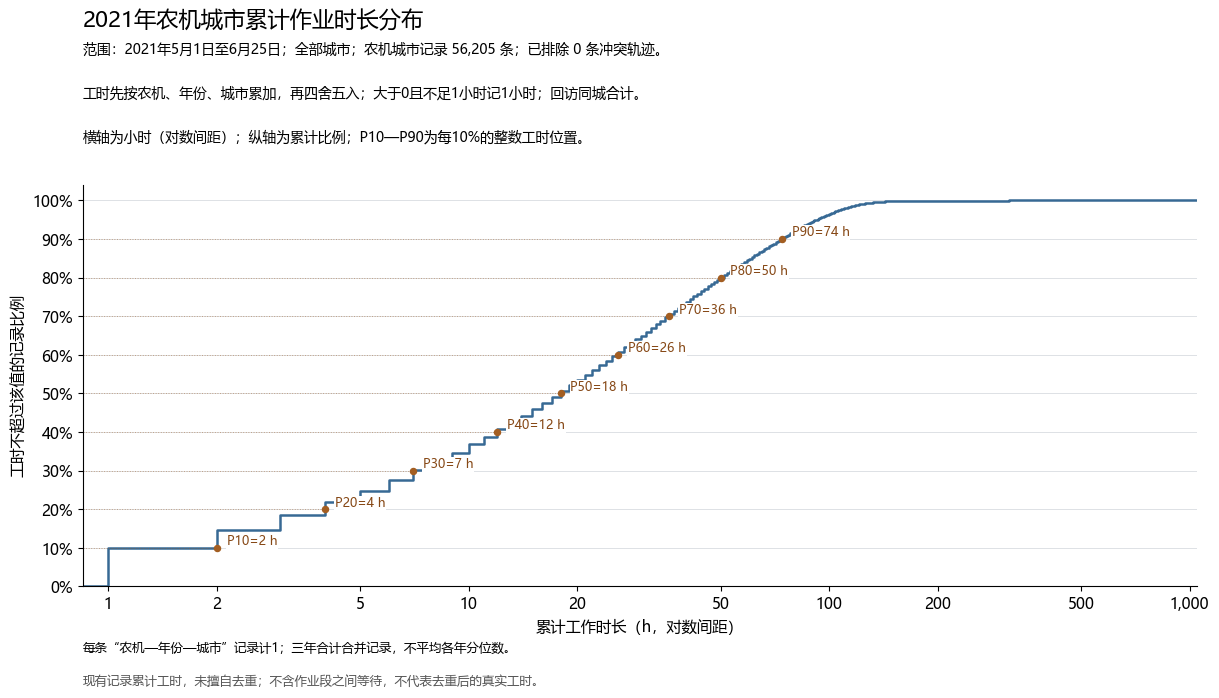

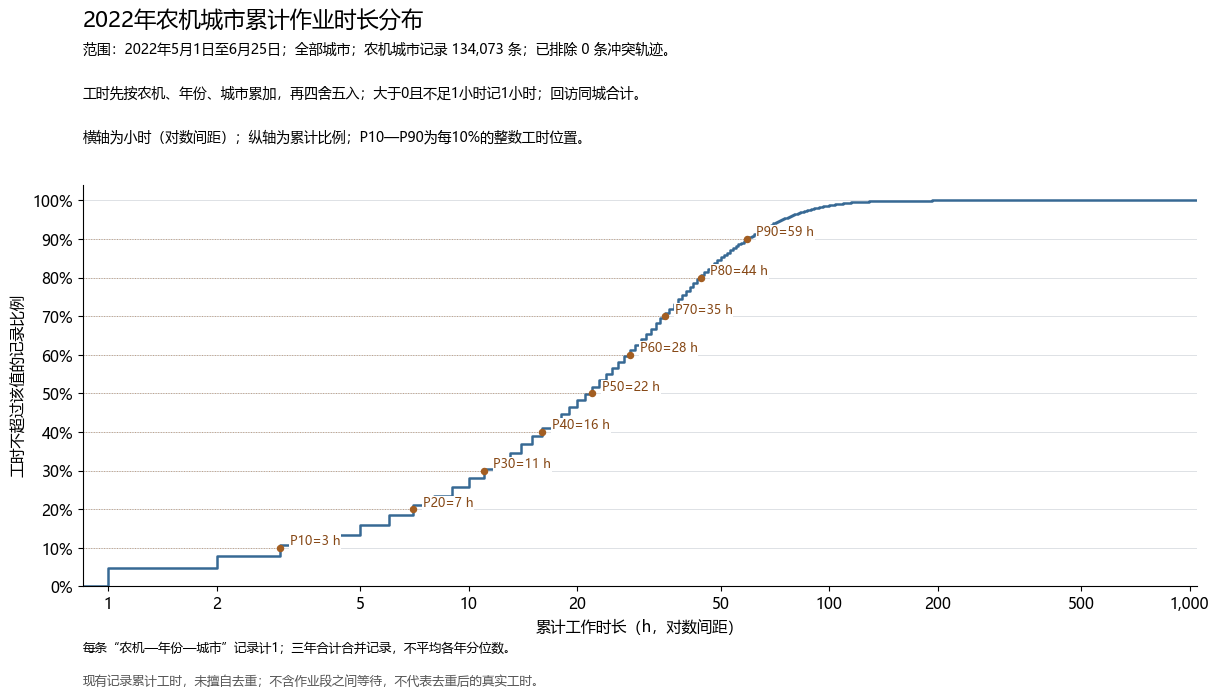

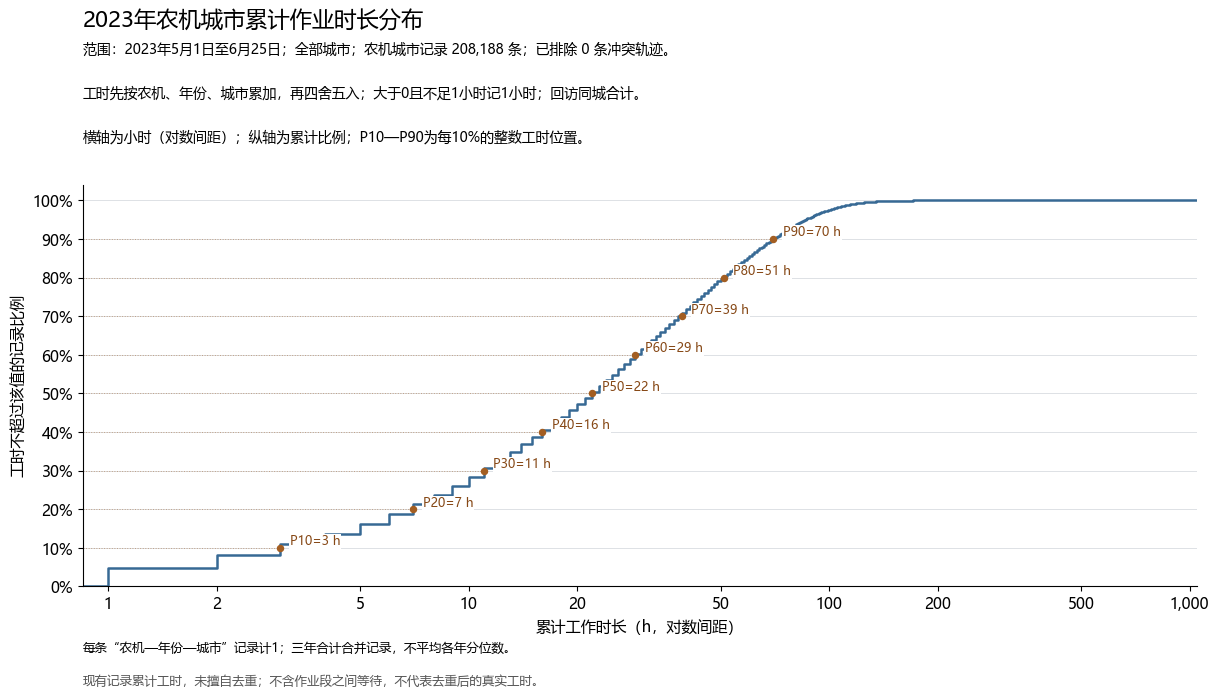

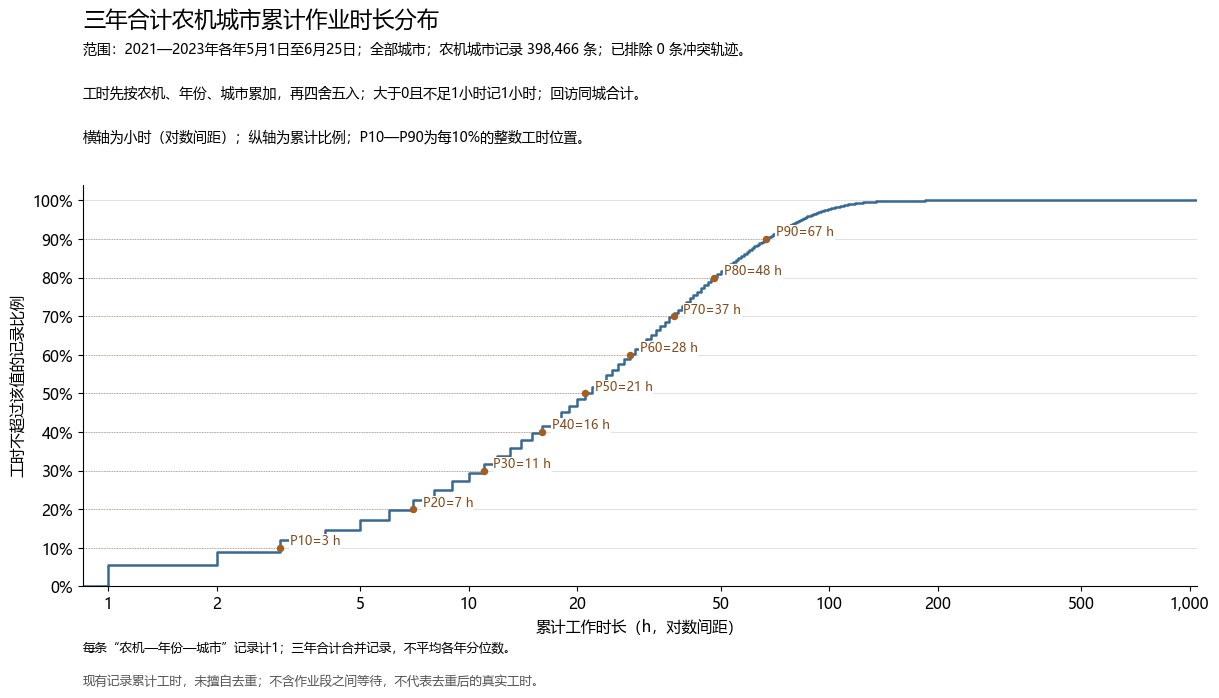

In [5]:
result_dir.mkdir(parents=True, exist_ok=True)
outputs = [(f'CITY_WORK_HOURS_{y}', detail_paths[y], details[y], '一行一个年份、农机和城市') for y in years]
outputs += [
    ('CITY_WORK_HOURS_DISTRIBUTION', statistics_path, statistics, '一行一个统计范围与实际出现的整数小时'),
    ('CITY_WORK_HOURS_QUANTILES', quantile_path, quantile_table, '一行一个年份或三年合计范围'),
    ('CITY_WORK_HOURS_EXCLUDED', excluded_path, excluded_table, '一行一条本次暂不统计的农机年度轨迹'),
    ('CITY_WORK_HOURS_CHECKS', check_path, check_table, '一行一个年份的运行检查')]
for _, path, table, _ in outputs:
    table.to_csv(path,index=False,encoding='utf-8-sig')
    saved = pd.read_csv(path,encoding='utf-8-sig',dtype='string',keep_default_na=False)
    expected = table.astype('string').fillna('')
    # 浮点小时与比例按数值读回核对，其余列逐格核对。
    float_columns = [c for c in table if pd.api.types.is_float_dtype(table[c])]
    for column in float_columns:
        assert np.allclose(pd.to_numeric(saved[column]),table[column],rtol=1e-12,atol=1e-12)
    pd.testing.assert_frame_equal(saved.drop(columns=float_columns),expected.drop(columns=float_columns),check_dtype=False)
fonts = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next((name for name in ['Microsoft YaHei','SimHei','Noto Sans CJK SC'] if name in fonts),None)
if chinese_font is None:
    raise RuntimeError('缺少中文字体，请安装微软雅黑、黑体或Noto Sans CJK SC后重跑。')
plt.rcParams.update({'font.sans-serif':[chinese_font],'axes.unicode_minus':False,'font.size':11})
maximum_hour = int(group_counts['三年合计'].index.max())
upper_x = maximum_hour * 1.15
x_ticks = [x for x in [1,2,5,10,20,50,100,200,500,1000,2000,5000] if x<=upper_x]
for scope,counts in group_counts.items():
    fig,ax = plt.subplots(figsize=(12.8,7.3))
    fig.subplots_adjust(left=0.10,right=0.97,bottom=0.18,top=0.73)
    title_scope = '三年合计' if scope=='三年合计' else scope+'年'
    period = '2021—2023年各年5月1日至6月25日' if scope=='三年合计' else scope+'年5月1日至6月25日'
    excluded_count = len(excluded_table) if scope=='三年合计' else int(check_table.set_index('年份').loc[int(scope),'排除轨迹数'])
    fig.suptitle(title_scope+'农机城市累计作业时长分布',x=0.10,y=0.97,ha='left',fontsize=16)
    fig.text(0.10,0.91,f'范围：{period}；全部城市；农机城市记录 {int(counts.sum()):,} 条；已排除 {excluded_count} 条冲突轨迹。',fontsize=10)
    fig.text(0.10,0.85,'工时先按农机、年份、城市累加，再四舍五入；大于0且不足1小时记1小时；回访同城合计。',fontsize=10)
    fig.text(0.10,0.79,'横轴为小时（对数间距）；纵轴为累计比例；P10—P90为每10%的整数工时位置。',fontsize=10)
    cumulative = counts.cumsum()/counts.sum()
    ax.step([0.85,*counts.index,upper_x],[0,*cumulative,1],where='post',color='#376994',linewidth=1.8)
    ax.set_xscale('log')
    ax.set(xlim=(0.85,upper_x),ylim=(0,1.04),xlabel='累计工作时长（h，对数间距）',
           ylabel='工时不超过该值的记录比例',xticks=x_ticks,yticks=np.arange(0,1.01,0.1))
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax.xaxis.set_minor_locator(ticker.NullLocator())
    ax.yaxis.set_major_formatter(ticker.PercentFormatter(1,decimals=0))
    ax.grid(axis='y',color='#d8dce0',linewidth=0.6)
    ax.spines[['top','right']].set_visible(False)
    for k,value in enumerate(decile_hours(counts),start=1):
        proportion = k/10
        ax.hlines(proportion,0.85,value,colors='#a35e22',linestyles=':',linewidth=0.7,alpha=0.5)
        ax.scatter(value,proportion,s=19,color='#a35e22',zorder=3)
        ax.annotate(f'P{k*10}={value} h',(value,proportion),xytext=(7,2),textcoords='offset points',
                    fontsize=9,color='#874917',bbox={'facecolor':'white','edgecolor':'none','pad':0.5})
    fig.text(0.10,0.09,'每条“农机—年份—城市”记录计1；三年合计合并记录，不平均各年分位数。',fontsize=9)
    fig.text(0.10,0.045,'现有记录累计工时，未擅自去重；不含作业段之间等待，不代表去重后的真实工时。',fontsize=9,color='#555555')
    fig.savefig(figure_paths[scope],dpi=170,facecolor='white')
    plt.show()
    plt.close(fig)


In [6]:
entries = []
for file_id,path,table,grain in outputs:
    entries.append({'file_id':file_id,'relative_path':path.relative_to(project_root).as_posix(),
        'file_name':path.name,'file_role':'descriptive_output','formal_status':'正式','read_only':'false',
        'year':str(int(table['年份'].iloc[0])) if file_id in {f'CITY_WORK_HOURS_{y}' for y in years} else '2021-2023',
        'time_range':'各年05-01至06-25','data_grain':grain,'row_count':str(len(table)),
        'file_size_bytes':str(path.stat().st_size),'sha256':fingerprint(path),'encoding':'UTF-8-SIG',
        'source_or_generator':notebook_relative,'upstream':'；'.join(input_hashes),
        'purpose':'描述农机在各城市的现有记录累计工时及其分布，不改研究链路',
        'notes':'排除冲突农机年度全部行及城市空值；按年、农机、城市先求和后小时四舍五入且最少1；不擅自去重'})
new_entries = pd.DataFrame(entries,columns=manifest_table.columns)
updated_manifest = pd.concat([manifest_table.loc[~manifest_table['file_id'].isin(new_entries['file_id'])],
                              new_entries],ignore_index=True)
assert not updated_manifest['file_id'].duplicated().any() and not updated_manifest['relative_path'].duplicated().any()
for relative,digest in input_hashes.items():
    assert fingerprint(project_root/relative)==digest,'输入在运行期间发生变化。'
assert all(path.is_file() and path.stat().st_size>0 for path in output_paths)
updated_manifest.to_csv(manifest_path,index=False,encoding='utf-8-sig')
print(f'完成：{sum(len(d) for d in details.values()):,}条农机城市记录，排除{len(excluded_table)}条冲突轨迹；七份CSV、四张P10—P90图。')


完成：398,466条农机城市记录，排除0条冲突轨迹；七份CSV、四张P10—P90图。
